# External validation on VinDr-CXR: dual-stream RAD-DINO verifier

Scores the **frozen** Stage 2 model from the dual-stream training notebook (frozen RAD-DINO CLS embedding of the proposal crop + 10-D thoracic geometry,
scored by the dual-stream MLP and by LightGBM) on VinDr-CXR proposals from the RT-DETR Stage 1 detector. Nothing is retrained or retuned.

Inputs to attach: (1) the training notebook's output (`dual_stream_verifier.pt`, `lightgbm_multimodal_verifier.joblib`, plus the two summary CSVs),
(2) the Stage 1 VinDr proposals (`vindr_proposals.csv`), (3) the VinBigData PNG dataset (images + `train_meta.csv`), (4) the VinBigData competition (`train.csv`).
Internet must be ON (Settings) so `microsoft/rad-dino` can be downloaded, or attach that model as an input.

Reported: AUROC/AUPRC with image-level bootstrap CIs, **TP retention and FP reduction** at the frozen operating point (alpha, tau) from RSNA,
FP reduction at matched TP retention, FP/img, and per-class TP retention. TP retention = share of true-positive proposals kept; FP reduction = share of false-positive proposals removed.

In [1]:
!pip install -q transformers lightgbm scikit-learn opencv-python-headless joblib matplotlib tqdm

In [2]:
import os, gc, re, hashlib
import cv2, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from tqdm.auto import tqdm
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print("device:", DEVICE, "| AMP:", USE_AMP)
if not torch.cuda.is_available():
    print("WARNING: no GPU - enable a GPU accelerator in notebook settings")

device: cuda | AMP: True


## 1. Configuration (edit only this cell)

In [3]:
# ================================ edit only this block ================================
# 1) Output folder of the dual-stream training notebook (attach that notebook as an input; copy the path from the Input panel)
ARTIFACT_DIR = "/kaggle/input/notebooks/prahlad214/aditya-s-notebook"

# 2) VinDr data
PROPOSALS_CSV   = "/kaggle/input/notebooks/prahlad214/rtdetr-vindrcxr/vindr_proposals.csv"
IMAGE_DIR       = "/kaggle/input/datasets/xhlulu/vinbigdata-chest-xray-resized-png-1024x1024/train"
ANNOTATIONS_CSV = "/kaggle/input/competitions/vinbigdata-chest-xray-abnormalities-detection/train.csv"
META_CSV        = "/kaggle/input/datasets/xhlulu/vinbigdata-chest-xray-resized-png-1024x1024/train_meta.csv"

# 3) Must equal the training notebook (check each against its printed output, see the notes in the chat)
CROP_PAD        = 0.10     # padding of the crops the verifier was trained on (pre-saved Stage 1 crops = 0.10; the notebook's dynamic fallback = 0.15)
TRAIN_BOX_SPACE = 1024.0   # pixel space of the boxes in the training proposals CSV (1024 if x2 reached ~1024, 640 if it stayed <= 640)
SPATIAL_NORM    = 1024.0   # img_w / img_h used by extract_spatial_features in training
MODEL_NAME, PROJ_DIM, DROPOUT = "microsoft/rad-dino", 32, 0.35

# 4) Frozen operating point from RSNA. None = read from the training notebook's summary CSVs
ALPHA, TAU, ACTIVE = None, None, None      # ACTIVE: "dual" or "lgbm"

# 5) Evaluation settings
CONF_CUTOFF, IOU_TP, N_BOOT = 0.15, 0.40, 1000
POSITIVE_CLASSES = ("Consolidation", "Infiltration", "Lung Opacity")
MIN_AGREE, CONSENSUS_IOU = 2, 0.4          # min_agree=2 for the 3-radiologist training split
EMBED_BATCH = 64
OUT_DIR = "/kaggle/working"
# ======================================================================================
os.makedirs(OUT_DIR, exist_ok=True)

## 2. Trained artifacts and frozen operating point

In [5]:
ART = dict(dual=f"{ARTIFACT_DIR}/experiments/raddino_spatial_output/dual_stream_verifier.pt",
           lgb=f"{ARTIFACT_DIR}/experiments/raddino_spatial_output/lightgbm_multimodal_verifier.joblib",
           summary=f"{ARTIFACT_DIR}/experiments/raddino_spatial_output/spatial_refinement_benchmark_summary.csv",
           ablation=f"{ARTIFACT_DIR}/experiments/raddino_spatial_output/spatial_ablation_metrics.csv")
for k, p in ART.items():
    print(os.path.exists(p), p)
missing = [ART[k] for k in ("dual", "lgb") if not os.path.exists(ART[k])]
if missing:
    raise FileNotFoundError(f"model files not found - attach the training notebook's output and fix ARTIFACT_DIR: {missing}")


def read_frozen_operating_point():
    alpha, tau, active = ALPHA, TAU, ACTIVE
    if (alpha is None or tau is None) and os.path.exists(ART["summary"]):
        text = " ".join(pd.read_csv(ART["summary"])["Stage / Model"].astype(str))
        m = re.search(r"tau=([0-9.]+),\s*alpha=([0-9.]+)", text)
        if m:
            tau = float(m.group(1)) if tau is None else tau
            alpha = float(m.group(2)) if alpha is None else alpha
    if active is None and os.path.exists(ART["ablation"]):
        ab = pd.read_csv(ART["ablation"])
        auc = {c[:2]: float(a) for c, a in zip(ab.Configuration, ab.AUROC)}
        if "3." in auc and "4." in auc:
            active = "dual" if auc["4."] >= auc["3."] else "lgbm"     # same rule as the training notebook
    if alpha is None or tau is None or active is None:
        raise ValueError(f"set ALPHA / TAU / ACTIVE manually in the config cell (found alpha={alpha}, tau={tau}, active={active}); "
                         "they are printed in the training notebook's final summary table")
    return float(alpha), float(tau), active


FROZEN_ALPHA, FROZEN_TAU, ACTIVE_NAME = read_frozen_operating_point()
print(f"frozen operating point: alpha={FROZEN_ALPHA}, tau={FROZEN_TAU}, active verifier={ACTIVE_NAME}")

True /kaggle/input/notebooks/prahlad214/aditya-s-notebook/experiments/raddino_spatial_output/dual_stream_verifier.pt
True /kaggle/input/notebooks/prahlad214/aditya-s-notebook/experiments/raddino_spatial_output/lightgbm_multimodal_verifier.joblib
True /kaggle/input/notebooks/prahlad214/aditya-s-notebook/experiments/raddino_spatial_output/spatial_refinement_benchmark_summary.csv
True /kaggle/input/notebooks/prahlad214/aditya-s-notebook/experiments/raddino_spatial_output/spatial_ablation_metrics.csv
frozen operating point: alpha=0.7, tau=0.3, active verifier=lgbm


## 3. Stage 1 proposals on VinDr

In [6]:
df = pd.read_csv(PROPOSALS_CSV)
df["patientId"] = df["patientId"].astype(str)
df["conf"] = df["confidence"].astype(float)
for new, old in (("bx1", "pred_x1"), ("by1", "pred_y1"), ("bx2", "pred_x2"), ("by2", "pred_y2")):
    df[new] = df[old].astype(float)
n_raw = len(df)
df = df[(df.conf >= CONF_CUTOFF) & (df.bx2 > df.bx1) & (df.by2 > df.by1)]
df = df.drop_duplicates(subset=["patientId", "bx1", "by1", "bx2", "by2"]).reset_index(drop=True)

IMG = {os.path.splitext(f)[0]: os.path.join(IMAGE_DIR, f) for f in os.listdir(IMAGE_DIR)
       if f.lower().endswith((".png", ".jpg", ".jpeg"))}
absent = set(df.patientId) - set(IMG)
if absent:
    print(f"WARNING: {len(absent)} proposal images not found in IMAGE_DIR")
    assert len(absent) / df.patientId.nunique() < 0.01, "more than 1% of images missing - check IMAGE_DIR"
    df = df[df.patientId.isin(IMG)].reset_index(drop=True)
print(f"proposals {len(df)}/{n_raw} | images {df.patientId.nunique()} | proposals/image {len(df) / df.patientId.nunique():.2f}")

proposals 8361/8361 | images 3467 | proposals/image 2.41


## 4. Crops, RAD-DINO embeddings and geometry features
Replicates the training notebook: a crop of the proposal with `CROP_PAD` padding (same truncation rules as the Stage 1 harvest cell) resized to 224x224 RGB,
the frozen RAD-DINO `[CLS]` embedding (FP16 on GPU), and the 10-D normalized geometry vector. Embeddings are computed in chunks and cached.

In [8]:
def crop_like_stage1(img, x1, y1, x2, y2, pad=CROP_PAD):
    h_img, w_img = img.shape[:2]
    w, h = x2 - x1, y2 - y1
    cx1, cy1 = max(0, int(x1 - pad * w)), max(0, int(y1 - pad * h))
    cx2, cy2 = min(w_img, int(x2 + pad * w)), min(h_img, int(y2 + pad * h))
    if cx2 <= cx1 or cy2 <= cy1:
        return None
    return cv2.resize(img[cy1:cy2, cx1:cx2], (224, 224), interpolation=cv2.INTER_LINEAR)


def spatial_features(df, wh):
    """Same 10-D vector as extract_spatial_features in training, with boxes mapped into the training box space first."""
    W, H = wh[:, 0], wh[:, 1]
    k = TRAIN_BOX_SPACE
    x1, y1 = df.bx1.values / W * k, df.by1.values / H * k
    x2, y2 = df.bx2.values / W * k, df.by2.values / H * k
    n1, m1, n2, m2 = (np.clip(v / SPATIAL_NORM, 0.0, 1.0) for v in (x1, y1, x2, y2))
    w, h = np.clip(n2 - n1, 1e-4, 1.0), np.clip(m2 - m1, 1e-4, 1.0)
    cx, cy = (n1 + n2) / 2.0, (m1 + m2) / 2.0
    return np.stack([n1, m1, n2, m2, cx, cy, w, h, w * h, np.abs(cx - 0.5)], 1).astype(np.float32)


def load_raddino():
    from transformers import AutoImageProcessor, AutoModel
    processor = AutoImageProcessor.from_pretrained(MODEL_NAME)
    backbone = AutoModel.from_pretrained(MODEL_NAME).eval().to(DEVICE)
    return processor, backbone


def make_embed_fn(processor, backbone):
    def embed(crops):
        inputs = processor(images=crops, return_tensors="pt").to(DEVICE)
        with torch.no_grad():
            if USE_AMP:
                with torch.autocast("cuda", dtype=torch.float16):
                    out = backbone(**inputs)
            else:
                out = backbone(**inputs)
        return out.last_hidden_state[:, 0, :].float().cpu().numpy()
    return embed


def extract_features(df, embed_fn):
    emb = np.zeros((len(df), 768), np.float32)
    wh = np.zeros((len(df), 2), np.float32)
    valid = np.zeros(len(df), bool)
    buf_idx, buf_img = [], []

    def flush():
        if buf_idx:
            emb[buf_idx] = embed_fn(buf_img)
            valid[buf_idx] = True
            buf_idx.clear(); buf_img.clear()

    for pid, g in tqdm(df.groupby("patientId"), total=df.patientId.nunique(), desc="embeddings"):
        raw = cv2.imread(IMG[pid])
        if raw is None:
            continue
        H, W = raw.shape[:2]
        rgb = cv2.cvtColor(raw, cv2.COLOR_BGR2RGB)
        for i, x1, y1, x2, y2 in zip(g.index, g.bx1, g.by1, g.bx2, g.by2):
            wh[i] = (W, H)
            crop = crop_like_stage1(rgb, x1, y1, x2, y2)
            if crop is None:
                continue
            buf_idx.append(i); buf_img.append(crop)
            if len(buf_idx) >= EMBED_BATCH:
                flush()
    flush()
    return emb, wh, valid

In [9]:
cache_key = hashlib.md5(df[["bx1", "by1", "bx2", "by2"]].values.tobytes() + str((CROP_PAD, MODEL_NAME)).encode()).hexdigest()[:10]
cache = os.path.join(OUT_DIR, f"vindr_features_{cache_key}.npz")
if os.path.exists(cache):
    z = np.load(cache); emb, wh, valid = z["emb"], z["wh"], z["valid"]
    print("[CACHE HIT]", cache)
else:
    processor, backbone = load_raddino()
    emb, wh, valid = extract_features(df, make_embed_fn(processor, backbone))
    np.savez(cache, emb=emb, wh=wh, valid=valid)
    del processor, backbone; gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

n_missing = int((~valid).sum())
print(f"valid embeddings {int(valid.sum())}/{len(valid)} (missing {n_missing})")
assert n_missing / len(valid) <= 0.01, "more than 1% of crops failed - check image paths"
df, emb, wh = df[valid].reset_index(drop=True), emb[valid], wh[valid]
out_of_image = ((df.bx2.values > wh[:, 0] * 1.01) | (df.by2.values > wh[:, 1] * 1.01)).mean()
assert out_of_image < 0.01, f"{out_of_image:.1%} of boxes fall outside the image - wrong box coordinate space"

S = spatial_features(df, wh)
print("geometry features", S.shape, "| mean", S.mean(0).round(3).tolist())

preprocessor_config.json:   0%|          | 0.00/756 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/879 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

embeddings:   0%|          | 0/3467 [00:00<?, ?it/s]

valid embeddings 8361/8361 (missing 0)
geometry features (8361, 10) | mean [0.3050000071525574, 0.41499999165534973, 0.5270000100135803, 0.6399999856948853, 0.41600000858306885, 0.527999997138977, 0.22200000286102295, 0.22499999403953552, 0.05299999937415123, 0.19699999690055847]


## 5. Ground truth on VinDr
Boxes of the positive classes are fused across radiologists (a box needs `MIN_AGREE` distinct radiologists with IoU >= `CONSENSUS_IOU`; coordinates averaged).
A proposal is a true positive at IoU >= `IOU_TP`, the same rule as RSNA. Labels are rescaled from the original DICOM size to the PNG size using `train_meta.csv`.

In [10]:
def pairwise_iou(a, b):
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)


def fuse_annotations(ann, classes, min_agree, iou_thr):
    rows = []
    positive = ann[ann.class_name.isin(classes)]
    for (image_id, cls), g in positive.groupby(["image_id", "class_name"]):
        boxes, rads = g[["x_min", "y_min", "x_max", "y_max"]].values.astype(float), g.rad_id.values
        iou, used = pairwise_iou(boxes, boxes), np.zeros(len(g), bool)
        for i in range(len(g)):
            if used[i]:
                continue
            members, seen = [i], {rads[i]}
            for j in range(i + 1, len(g)):
                if not used[j] and rads[j] not in seen and iou[i, j] >= iou_thr:
                    members.append(j); seen.add(rads[j])
            used[members] = True
            if len(seen) >= min_agree:
                rows.append((image_id, cls, *boxes[members].mean(0)))
    return pd.DataFrame(rows, columns=["image_id", "cls", "x1", "y1", "x2", "y2"])


def attach_labels(df, wh, gt, meta, iou_tp):
    df = df.copy()
    df["iou"], df["gt_class"] = 0.0, ""
    gt_by_image = {k: g for k, g in gt.groupby("image_id")}
    for pid, g in df.groupby("patientId"):
        gg = gt_by_image.get(pid)
        if gg is None:
            continue
        boxes = gg[["x1", "y1", "x2", "y2"]].values.astype(float)
        w0, h0 = meta[pid]
        w, h = wh[g.index[0]]
        boxes = boxes * np.array([w / w0, h / h0, w / w0, h / h0])
        iou = pairwise_iou(g[["bx1", "by1", "bx2", "by2"]].values, boxes)
        df.loc[g.index, "iou"] = iou.max(1)
        df.loc[g.index, "gt_class"] = gg["cls"].values[iou.argmax(1)]
    df["is_tp"] = (df.iou >= iou_tp).astype(int)
    df.loc[df.is_tp == 0, "gt_class"] = ""
    return df


ann = pd.read_csv(ANNOTATIONS_CSV)
ann["image_id"] = ann["image_id"].astype(str)
assert {"class_name", "rad_id", "x_min", "y_min", "x_max", "y_max"} <= set(ann.columns), f"annotation columns: {list(ann.columns)}"
gt = fuse_annotations(ann, POSITIVE_CLASSES, MIN_AGREE, CONSENSUS_IOU)
m = pd.read_csv(META_CSV)
meta = {str(i): (float(w), float(h)) for i, h, w in zip(m.image_id, m.dim0, m.dim1)}
assert set(df.patientId) <= set(meta), "images missing from META_CSV"
print(f"fused GT boxes {len(gt)} on {gt.image_id.nunique()} images | per class:", gt.cls.value_counts().to_dict())

df = attach_labels(df, wh, gt, meta, IOU_TP)
y = df.is_tp.values.astype(int)
print(f"TP rate {y.mean():.3f} | images with a TP proposal {df[df.is_tp == 1].patientId.nunique()}/{df.patientId.nunique()} | "
      f"detector-conf AUROC {roc_auc_score(y, df.conf):.4f} AUPRC {average_precision_score(y, df.conf):.4f}")

fused GT boxes 803 on 602 images | per class: {'Lung Opacity': 449, 'Infiltration': 248, 'Consolidation': 106}
TP rate 0.112 | images with a TP proposal 336/3467 | detector-conf AUROC 0.6982 AUPRC 0.2780


## 6. Frozen Stage 2 models

In [11]:
def build_dual_model():
    import torch.nn as nn

    class DualStreamVerifier(nn.Module):          # identical to the training notebook
        def __init__(self, vision_dim=768, spatial_dim=10, proj_dim=PROJ_DIM, dropout=DROPOUT):
            super().__init__()
            self.vision_branch = nn.Sequential(nn.Linear(vision_dim, proj_dim), nn.LayerNorm(proj_dim), nn.GELU(), nn.Dropout(dropout))
            self.spatial_branch = nn.Sequential(nn.Linear(spatial_dim, proj_dim), nn.LayerNorm(proj_dim), nn.GELU(), nn.Dropout(dropout))
            self.classifier = nn.Sequential(nn.Linear(proj_dim * 2, proj_dim), nn.LayerNorm(proj_dim), nn.GELU(),
                                            nn.Dropout(dropout), nn.Linear(proj_dim, 1))

        def forward(self, v, s):
            return self.classifier(torch.cat([self.vision_branch(v), self.spatial_branch(s)], dim=-1))

    return DualStreamVerifier()


def score_dual_stream(V, S):
    model = build_dual_model().to(DEVICE)
    model.load_state_dict(torch.load(ART["dual"], map_location=DEVICE))
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(V), 4096):
            v = torch.from_numpy(V[i:i + 4096]).float().to(DEVICE)
            s = torch.from_numpy(S[i:i + 4096]).float().to(DEVICE)
            out.append(torch.sigmoid(model(v, s)).squeeze(1).cpu().numpy())
    return np.concatenate(out)


def score_lgbm(V, S):
    return joblib.load(ART["lgb"]).predict_proba(np.hstack([V, S]))[:, 1]

In [12]:
p_dual = score_dual_stream(emb, S)
p_lgbm = score_lgbm(emb, S)
p_active = p_dual if ACTIVE_NAME == "dual" else p_lgbm
p_other = p_lgbm if ACTIVE_NAME == "dual" else p_dual
det = df.conf.values.astype(np.float32)
fused = FROZEN_ALPHA * det + (1.0 - FROZEN_ALPHA) * p_active          # same fusion rule as the training notebook
fused_other = FROZEN_ALPHA * det + (1.0 - FROZEN_ALPHA) * p_other
names = dict(dual="Dual-stream verifier", lgbm="LightGBM multimodal")
fused_name = f"Fused: {FROZEN_ALPHA:.2f} x detector + {1 - FROZEN_ALPHA:.2f} x {names[ACTIVE_NAME]}"
print("score ranges  detector", det.min().round(3), det.max().round(3), "| dual", p_dual.min().round(3), p_dual.max().round(3),
      "| lgbm", p_lgbm.min().round(3), p_lgbm.max().round(3))

score ranges  detector 0.15 0.652 | dual 0.021 0.939 | lgbm 0.077 0.585


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


## 7. Evaluation
AUROC/AUPRC use an image-level bootstrap. AUPRC depends on the base rate, so compare AUROC, TP retention and FP reduction across datasets, not AUPRC.
The frozen (alpha, tau) is applied as selected on RSNA. The matched-retention table picks thresholds on VinDr labels, so it is a ranking comparison only.

In [13]:
def ci95(values):
    return np.percentile(values, 2.5), np.percentile(values, 97.5)


def image_bootstrap(codes, n_boot, seed):
    order = np.argsort(codes, kind="stable")
    _, starts = np.unique(codes[order], return_index=True)
    groups = np.split(order, starts[1:])
    rng = np.random.default_rng(seed)
    return len(groups), [np.concatenate([groups[j] for j in rng.integers(0, len(groups), len(groups))]) for _ in range(n_boot)]


def ranking_row(name, y, s, boots):
    roc = ci95([roc_auc_score(y[b], s[b]) for b in boots])
    pr = ci95([average_precision_score(y[b], s[b]) for b in boots])
    return dict(method=name, AUROC=f"{roc_auc_score(y, s):.4f} [{roc[0]:.3f}-{roc[1]:.3f}]",
                AUPRC=f"{average_precision_score(y, s):.4f} [{pr[0]:.3f}-{pr[1]:.3f}]")


def paired_delta_auprc(y, s_a, s_b, boots):
    diffs = [average_precision_score(y[b], s_a[b]) - average_precision_score(y[b], s_b[b]) for b in boots]
    lo, hi = ci95(diffs)
    return average_precision_score(y, s_a) - average_precision_score(y, s_b), lo, hi


def retention_fpred(y, s, tau):
    kept = s >= tau
    tp, fp = (y * kept).sum(), ((1 - y) * kept).sum()
    return tp / y.sum(), 1 - fp / (1 - y).sum(), fp, tp / max(tp + fp, 1)


def at_tp_retention(y, s, target):
    order = np.argsort(-s, kind="stable")
    i = min(np.searchsorted(np.cumsum(y[order]) / y.sum(), target), len(y) - 1)
    return retention_fpred(y, s, s[order][i])


n_images, boots = image_bootstrap(pd.factorize(df.patientId)[0], N_BOOT, SEED)
base_fp_img = (1 - y).sum() / n_images
methods = {"Detector conf": det, "LightGBM multimodal": p_lgbm, "Dual-stream verifier": p_dual, fused_name: fused}

print("=" * 92)
print(f"EXTERNAL TEST: {len(y)} proposals, {int(y.sum())} TPs ({y.mean():.3f} base rate), {n_images} images")
print("=" * 92)
ranking = pd.DataFrame([ranking_row(n, y, s, boots) for n, s in methods.items()])
print(ranking.to_string(index=False))
d, lo, hi = paired_delta_auprc(y, fused, det, boots)
print(f"\npaired dAUPRC fused - detector conf: {d:+.4f} [{lo:+.4f}, {hi:+.4f}]  ({'significant' if lo > 0 or hi < 0 else 'NOT significant'})")

rows = []
for name, s in (("Detector conf >= tau", det), (f"{fused_name} >= tau", fused),
                (f"{names['lgbm' if ACTIVE_NAME == 'dual' else 'dual']} fused, same alpha/tau", fused_other)):
    r, f, fp, prec = retention_fpred(y, s, FROZEN_TAU)
    rows.append(dict(scorer=name, tp_retention_pct=round(100 * r, 1), fp_reduction_pct=round(100 * f, 1),
                     precision_pct=round(100 * prec, 1), fp_per_img=round(fp / n_images, 3)))
frozen = pd.DataFrame(rows)
print(f"\nFROZEN RSNA operating point: alpha={FROZEN_ALPHA}, tau={FROZEN_TAU} | baseline FP/img = {base_fp_img:.3f} | TPs {int(y.sum())}, FPs {int((1 - y).sum())}")
print(frozen.to_string(index=False))

rows = []
for target in (0.80, 0.90, 0.95):
    for name, s in methods.items():
        r, f, fp, _ = at_tp_retention(y, s, target)
        rows.append(dict(target_tp_retention=f"{target:.0%}", method=name, actual_tp_retention_pct=round(100 * r, 1),
                         fp_reduction_pct=round(100 * f, 1), fp_per_img=round(fp / n_images, 3)))
matched = pd.DataFrame(rows)
print("\nFP reduction at matched TP retention (higher is better; thresholds picked on VinDr labels):")
print(matched.to_string(index=False))

kept = fused >= FROZEN_TAU
per_class = pd.DataFrame([dict(gt_class=c, tp_proposals=len(g), tp_retention_at_frozen_tau=round(float(kept[g.index].mean()), 3))
                          for c, g in df[df.is_tp == 1].groupby("gt_class")])
print("\nper-class TP retention at the frozen operating point:")
print(per_class.to_string(index=False))

EXTERNAL TEST: 8361 proposals, 938 TPs (0.112 base rate), 3467 images
                                             method                AUROC                AUPRC
                                      Detector conf 0.6982 [0.677-0.719] 0.2780 [0.238-0.315]
                                LightGBM multimodal 0.5001 [0.474-0.523] 0.1141 [0.101-0.131]
                               Dual-stream verifier 0.5871 [0.557-0.615] 0.1592 [0.133-0.190]
Fused: 0.70 x detector + 0.30 x LightGBM multimodal 0.6792 [0.656-0.702] 0.2630 [0.225-0.300]

paired dAUPRC fused - detector conf: -0.0150 [-0.0250, -0.0056]  (significant)

FROZEN RSNA operating point: alpha=0.7, tau=0.3 | baseline FP/img = 2.141 | TPs 938, FPs 7423
                                                    scorer  tp_retention_pct  fp_reduction_pct  precision_pct  fp_per_img
                                      Detector conf >= tau              39.6              86.9           27.6       0.281
Fused: 0.70 x detector + 0.30 x LightGBM 

## 8. Plots and saved outputs

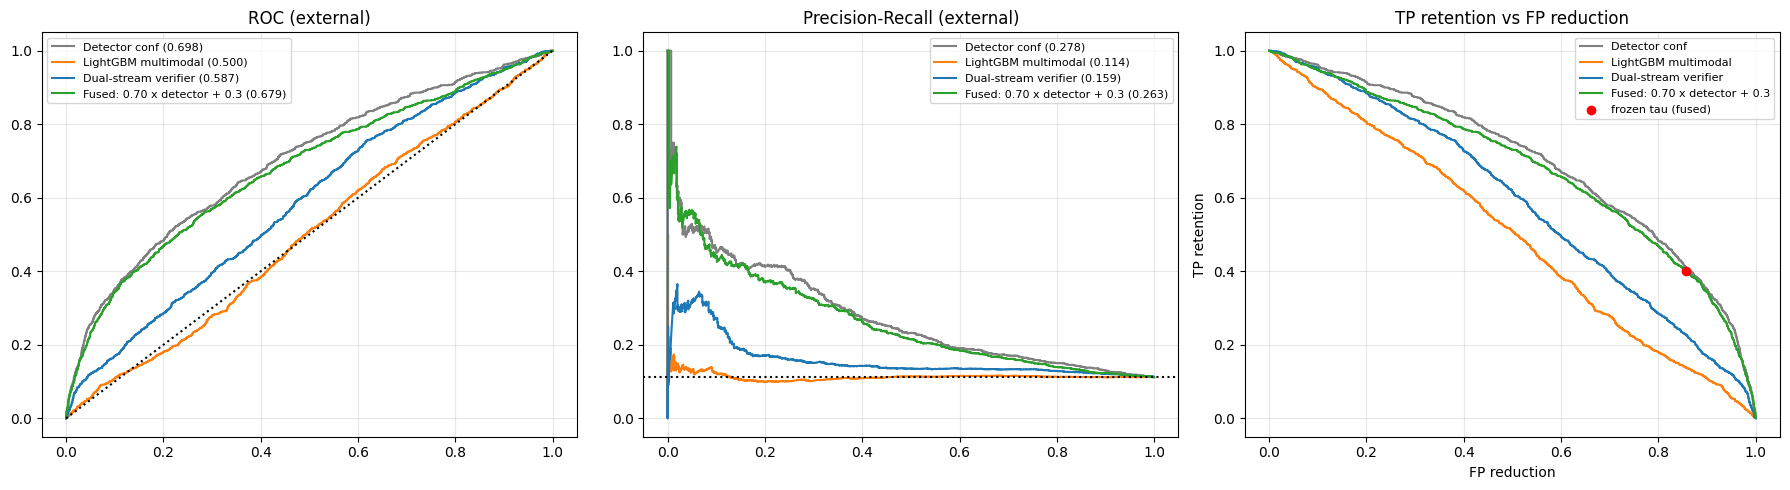

saved -> /kaggle/working


In [14]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
colors = {"Detector conf": "gray", "LightGBM multimodal": "tab:orange", "Dual-stream verifier": "tab:blue", fused_name: "tab:green"}
for name, s in methods.items():
    c = colors[name]
    fpr, tpr, _ = roc_curve(y, s); ax[0].plot(fpr, tpr, color=c, label=f"{name[:28]} ({roc_auc_score(y, s):.3f})")
    prec, rec, _ = precision_recall_curve(y, s); ax[1].plot(rec, prec, color=c, label=f"{name[:28]} ({average_precision_score(y, s):.3f})")
    order = np.argsort(-s, kind="stable")
    ax[2].plot(1 - np.cumsum(1 - y[order]) / (1 - y).sum(), np.cumsum(y[order]) / y.sum(), color=c, label=name[:28])
r, f, _, _ = retention_fpred(y, fused, FROZEN_TAU)
ax[2].scatter([f], [r], color="red", zorder=5, label="frozen tau (fused)")
ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set_title("ROC (external)")
ax[1].axhline(y.mean(), color="k", ls=":"); ax[1].set_title("Precision-Recall (external)")
ax[2].set_xlabel("FP reduction"); ax[2].set_ylabel("TP retention"); ax[2].set_title("TP retention vs FP reduction")
for a in ax:
    a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "external_results.png"), dpi=200); plt.show()

out = df.copy()
out["p_dual"], out["p_lgbm"], out["fused"] = p_dual, p_lgbm, fused
out.to_csv(os.path.join(OUT_DIR, "external_predictions.csv"), index=False)
ranking.to_csv(os.path.join(OUT_DIR, "external_ranking.csv"), index=False)
frozen.to_csv(os.path.join(OUT_DIR, "external_frozen_operating_point.csv"), index=False)
matched.to_csv(os.path.join(OUT_DIR, "external_matched_retention.csv"), index=False)
per_class.to_csv(os.path.join(OUT_DIR, "external_per_class.csv"), index=False)
print("saved ->", OUT_DIR)